# SC4002: Natural Language Processing Project

## Task: Build a system that identifies user's intent and extracts the slots in an English Assistance request. It involves two stages:
1. Task 1: Develop a baseline independently, without Generative AI assistance.
2. Task 2: Collaborate with AI to diagnose weaknesses, implement improvements.

Evaluate the resulting models from the above two stages. Submit reproducible notebook evidence, chat history with AI and a report of no more than two pages.

* Data can be found here "https://amazon-massive-nlu-dataset.s3.amazonaws.com/amazon-massive-dataset-1.0.tar.gz", en-US.jsonl file

In [1]:
# Necessary Files needed for Project

import time

# Read json file
import json

# Data Manipulation Libraries
import numpy as np
import pandas as pd
import sklearn
from sklearn.preprocessing import LabelEncoder

# Visualisation Libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

In [2]:
# Initialise all global variables
df = train_df = test_df = dev_df = pd.DataFrame()
label_encoder = LabelEncoder()

In [3]:
# Step 1: Extracting data from jsonl file to dataframes

try: 
    df = pd.read_json('data/en-US.jsonl', lines=True)
    print(df.head())
    print(df.columns)
except FileNotFoundError:
    print("ERROR: File not found")
except json.JSONDecodeError:
    print("ERROR: Invalid Json format in the file")

   id locale partition scenario             intent  \
0   0  en-US      test    alarm          alarm_set   
1   1  en-US     train    alarm          alarm_set   
2   2  en-US     train    alarm          alarm_set   
3   3  en-US      test    audio  audio_volume_mute   
4   4  en-US     train    audio  audio_volume_mute   

                                   utt  \
0      wake me up at five am this week   
1      wake me up at nine am on friday   
2  set an alarm for two hours from now   
3                                quiet   
4                           olly quiet   

                                           annot_utt  worker_id  
0  wake me up at [time : five am] [date : this week]          1  
1  wake me up at [time : nine am] on [date : friday]          1  
2       set an alarm for [time : two hours from now]          1  
3                                              quiet          1  
4                                         olly quiet          1  
Index(['id', 'locale', 'pa

In [4]:
# Print out how many train, test and dev datas in the Dataframe
print(df['partition'].value_counts())

partition
train    11514
test      2974
dev       2033
Name: count, dtype: int64


In [5]:
# Convert all 'intent' strings into int for easy calculation

# First, find out what are the different values in 'intent'
print(df['intent'].unique())

<StringArray>
[               'alarm_set',        'audio_volume_mute',
      'iot_hue_lightchange',         'iot_hue_lightoff',
          'iot_hue_lighton',         'iot_hue_lightdim',
             'iot_cleaning',           'calendar_query',
               'play_music',           'general_quirky',
            'general_greet',           'datetime_query',
         'datetime_convert',           'takeaway_query',
             'alarm_remove',              'alarm_query',
               'news_query',           'music_likeness',
              'music_query',          'iot_hue_lightup',
           'takeaway_order',            'weather_query',
           'music_settings',        'audio_volume_down',
             'general_joke',        'music_dislikeness',
       'audio_volume_other',               'iot_coffee',
          'audio_volume_up',              'iot_wemo_on',
             'iot_wemo_off',                 'qa_stock',
               'play_radio',              'social_post',
 'recommendation_

In [6]:
# Step 2: Separate the Dataframes into the different partitions and clean data
train_df = df[df['partition'] == 'train'].copy()
test_df = df[df['partition'] == 'test'].copy()
dev_df = df[df['partition'] == 'dev'].copy()

# Simple Cleaning Function
def clean_text(text):
    text = text.lower()
    # Remove basic punctuations but keep spaces
    import re
    text = re.sub(r'[^\w\s]','',text)
    return text

# Apply cleaning to the utterance ('utt' column)
train_df['utt_cleaned'] = train_df['utt'].apply(clean_text)
test_df['utt_cleaned'] = test_df['utt'].apply(clean_text)

# Encode the Target Labels
train_labels = label_encoder.fit_transform(train_df['intent'])
test_labels = label_encoder.transform(test_df['intent'])

print(f"Training set size: {len(train_df)}")
print(f"Testing set size: {len(test_df)}")
print(f"Number of unique intents: {len(label_encoder.classes_)}")

Training set size: 11514
Testing set size: 2974
Number of unique intents: 60


In [7]:
tfdif = TfidfVectorizer(ngram_range = (1,2), stop_words=None)

X_train = tfdif.fit_transform(train_df['utt_cleaned'])
X_test = tfdif.transform(test_df['utt_cleaned'])

Y_train = train_labels
Y_test = test_labels

print(f"Feature matrix shape: {X_train.shape}")

Feature matrix shape: (11514, 29284)


In [8]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train, Y_train)

print("Model Training Completed")

Model Training Completed


In [14]:
start_time = time.time()
Y_pred = model.predict(X_test)
end_time = time.time()

total_predicted_time = end_time - start_time
avg_time_per_sample = (total_predicted_time / X_test.shape[0]) * 1000 # in milliseconds

intent_acc = accuracy_score(Y_test, Y_pred) * 100

all_labels = range(len(label_encoder.classes_))

print("="*60)
print("TASK 1: Prediction Model using Logistic Regression")
print("="*60)
# Following the Assignment format
print(f"{'Metric':<20} | {'Value':<20}")
print("-" * 42)
print(f"{'Intent accuracy':<20} | {intent_acc:.2f}%")
print(f"{'Slot micro F1':<20} | N/A (Task 2)") # Placeholder for Task 2
print("-" * 42)

# Adding the time analysis below the required metrics
print(f"{'Total Pred Time':<20} | {total_predicted_time:.4f} s")
print(f"{'Avg Time per Utt':<20} | {avg_time_per_sample:.4f} ms")
print("="*60)

TASK 1: Prediction Model using Logistic Regression
Metric               | Value               
------------------------------------------
Intent accuracy      | 78.08%
Slot micro F1        | N/A (Task 2)
------------------------------------------
Total Pred Time      | 0.0094 s
Avg Time per Utt     | 0.0031 ms


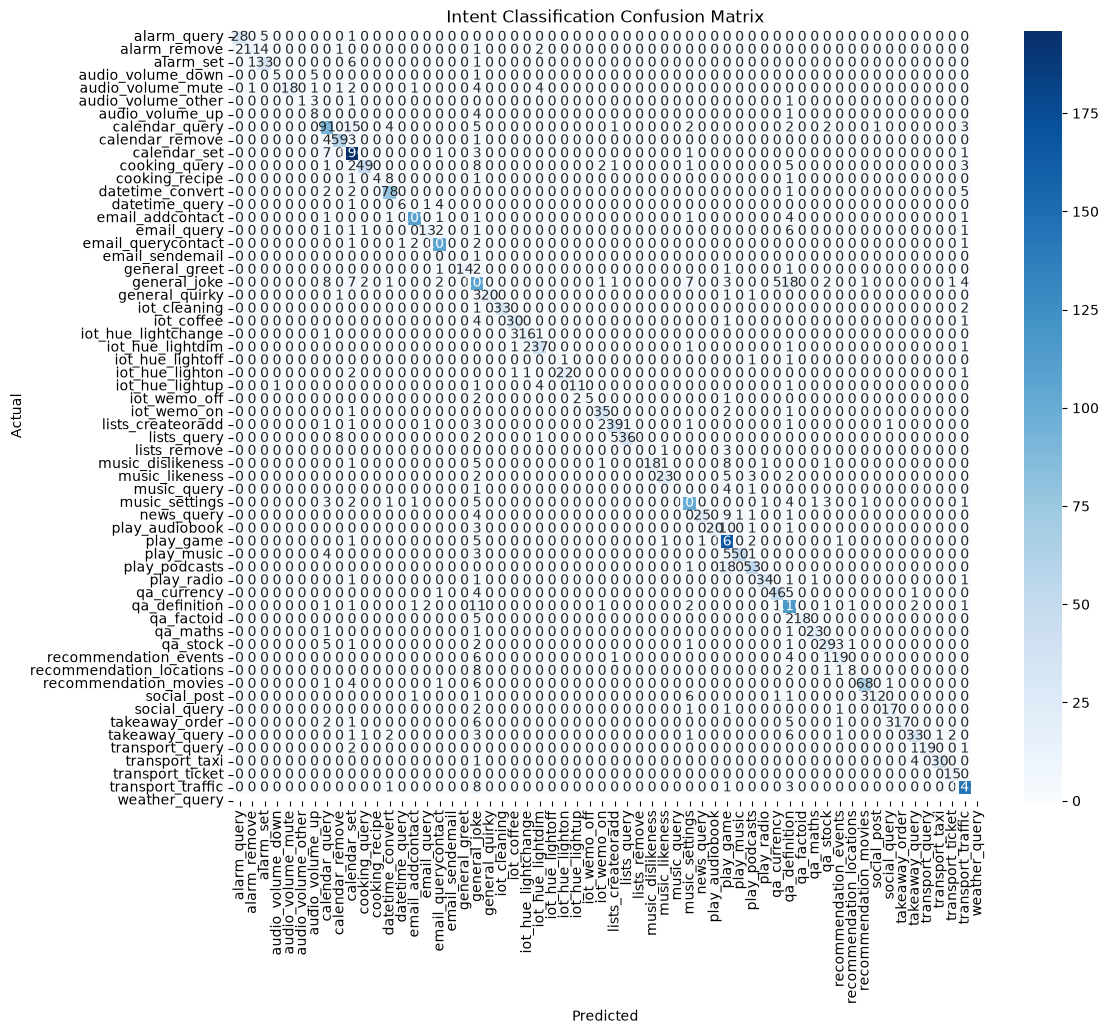

In [13]:
plt.figure(figsize=(12,10))
cm = confusion_matrix(Y_test, Y_pred)
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_,
            cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Intent Classification Confusion Matrix")
plt.show()